# HSV associative recall

Companion to *Voronoi-Based Activation Functions and Inertial Energy for Complex-Valued Hopfield Networks*.

## Goal
Run the same implementation as the paper with explicit inputs and outputs. The public setup downloads the tagged source without GitHub credentials. Full mode follows the paper protocol; smoke mode is an execution check. The final cell exports this run.

## Setup
Select a CPU runtime and run all cells in order. On Google Colab, setup clones the public release and installs its requirements. Locally, install requirements.txt and open the notebook from the extracted repository.

In [1]:
from pathlib import Path
import os, sys, subprocess, uuid, json

REPOSITORY = "https://github.com/Fideliszan/complex-valued-voronoi-hopfield.git"
REVISION = "v1.0.1"
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    ROOT = Path("/content") / ("complex_voronoi_" + uuid.uuid4().hex[:8])
    subprocess.run(["git", "clone", "--quiet", "--depth", "1", "--branch", REVISION,
                    REPOSITORY, str(ROOT)], check=True, capture_output=True, text=True)
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    ROOT = next((p for p in candidates if (p / "src/cvhnn").is_dir()), None)
    if ROOT is None:
        raise RuntimeError("Open this notebook from an extracted repository directory.")
os.environ["MPLCONFIGDIR"] = str(ROOT / "runs/matplotlib")
print("Project:", ROOT.name)
print("Runtime:", "Google Colab" if IN_COLAB else "local")
print("Source:", REVISION if IN_COLAB else "local checkout")


Project: complex-valued-voronoi-hopfield
Runtime: local
Source: local checkout


In [2]:
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")], check=True)
print("Setup complete.")


Setup complete.


## Configuration
Smoke mode checks execution with fewer trials. Full mode uses the paper protocol. Existing output directories are never overwritten.

In [3]:
MODE = "full"
OUTPUT = ROOT / "runs" / ("02_hsv_recall_" + uuid.uuid4().hex[:8])
print("Mode:", MODE)

Mode: full


## Execute

In [4]:
command = [sys.executable, str(ROOT / "scripts/run_experiment.py"), "recall", "--mode", MODE, "--output", str(OUTPUT)]
completed = subprocess.run(command, cwd=ROOT, capture_output=True, text=True)
print("Experiment completed successfully." if completed.returncode == 0 else completed.stdout[-1200:])
if completed.returncode:
    print(completed.stderr[-3000:])
    raise RuntimeError("Experiment failed; inspect the message above.")
print("Execution record:", json.loads((OUTPUT / "execution.json").read_text())["seconds"], "seconds")

import platform, hashlib, datetime, importlib.metadata
runtime_record = {
    "mode": MODE, "host": "Google Colab" if IN_COLAB else "local",
    "platform": platform.platform(), "python": sys.version,
    "utc_finished": datetime.datetime.now(datetime.timezone.utc).isoformat(),
    "source_files_sha256": {str(p.relative_to(ROOT)).replace(chr(92), "/"): hashlib.sha256(p.read_bytes()).hexdigest()
                            for p in sorted((ROOT / "src/cvhnn").glob("*.py"))},
    "packages": {p: importlib.metadata.version(p) for p in
                 ["numpy", "pandas", "scipy", "matplotlib", "seaborn", "plotnine"]},
}
(OUTPUT / "notebook_runtime.json").write_text(json.dumps(runtime_record, indent=2))
print("Environment:", runtime_record["packages"])


Experiment completed successfully.
Execution record: 219.9484603999881 seconds
Environment: {'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'plotnine': '0.15.8'}


## Results and checks

SER  exact_recovery
alphabet     corruption_kind rule                           
61-Hexagonal hsv             classic  0.9968             0.0
                             voronoi  0.0000             1.0
             symbol          classic  0.9968             0.0
                             voronoi  0.0000             1.0
64-PSK       hsv             classic  0.1777             0.6
                             voronoi  0.1777             0.6
             symbol          classic  0.0000             1.0
                             voronoi  0.0000             1.0
64-Polar     hsv             classic  0.9964             0.0
                             voronoi  0.8196             0.0
             symbol          classic  0.9964             0.0
                             voronoi  0.2001             0.7
64-QAM       hsv             classic  0.9964             0.0
                             voronoi  0.0543             0.9
             symbol          classic  0.9964             0.0
                             voronoi  0.0000             1.0

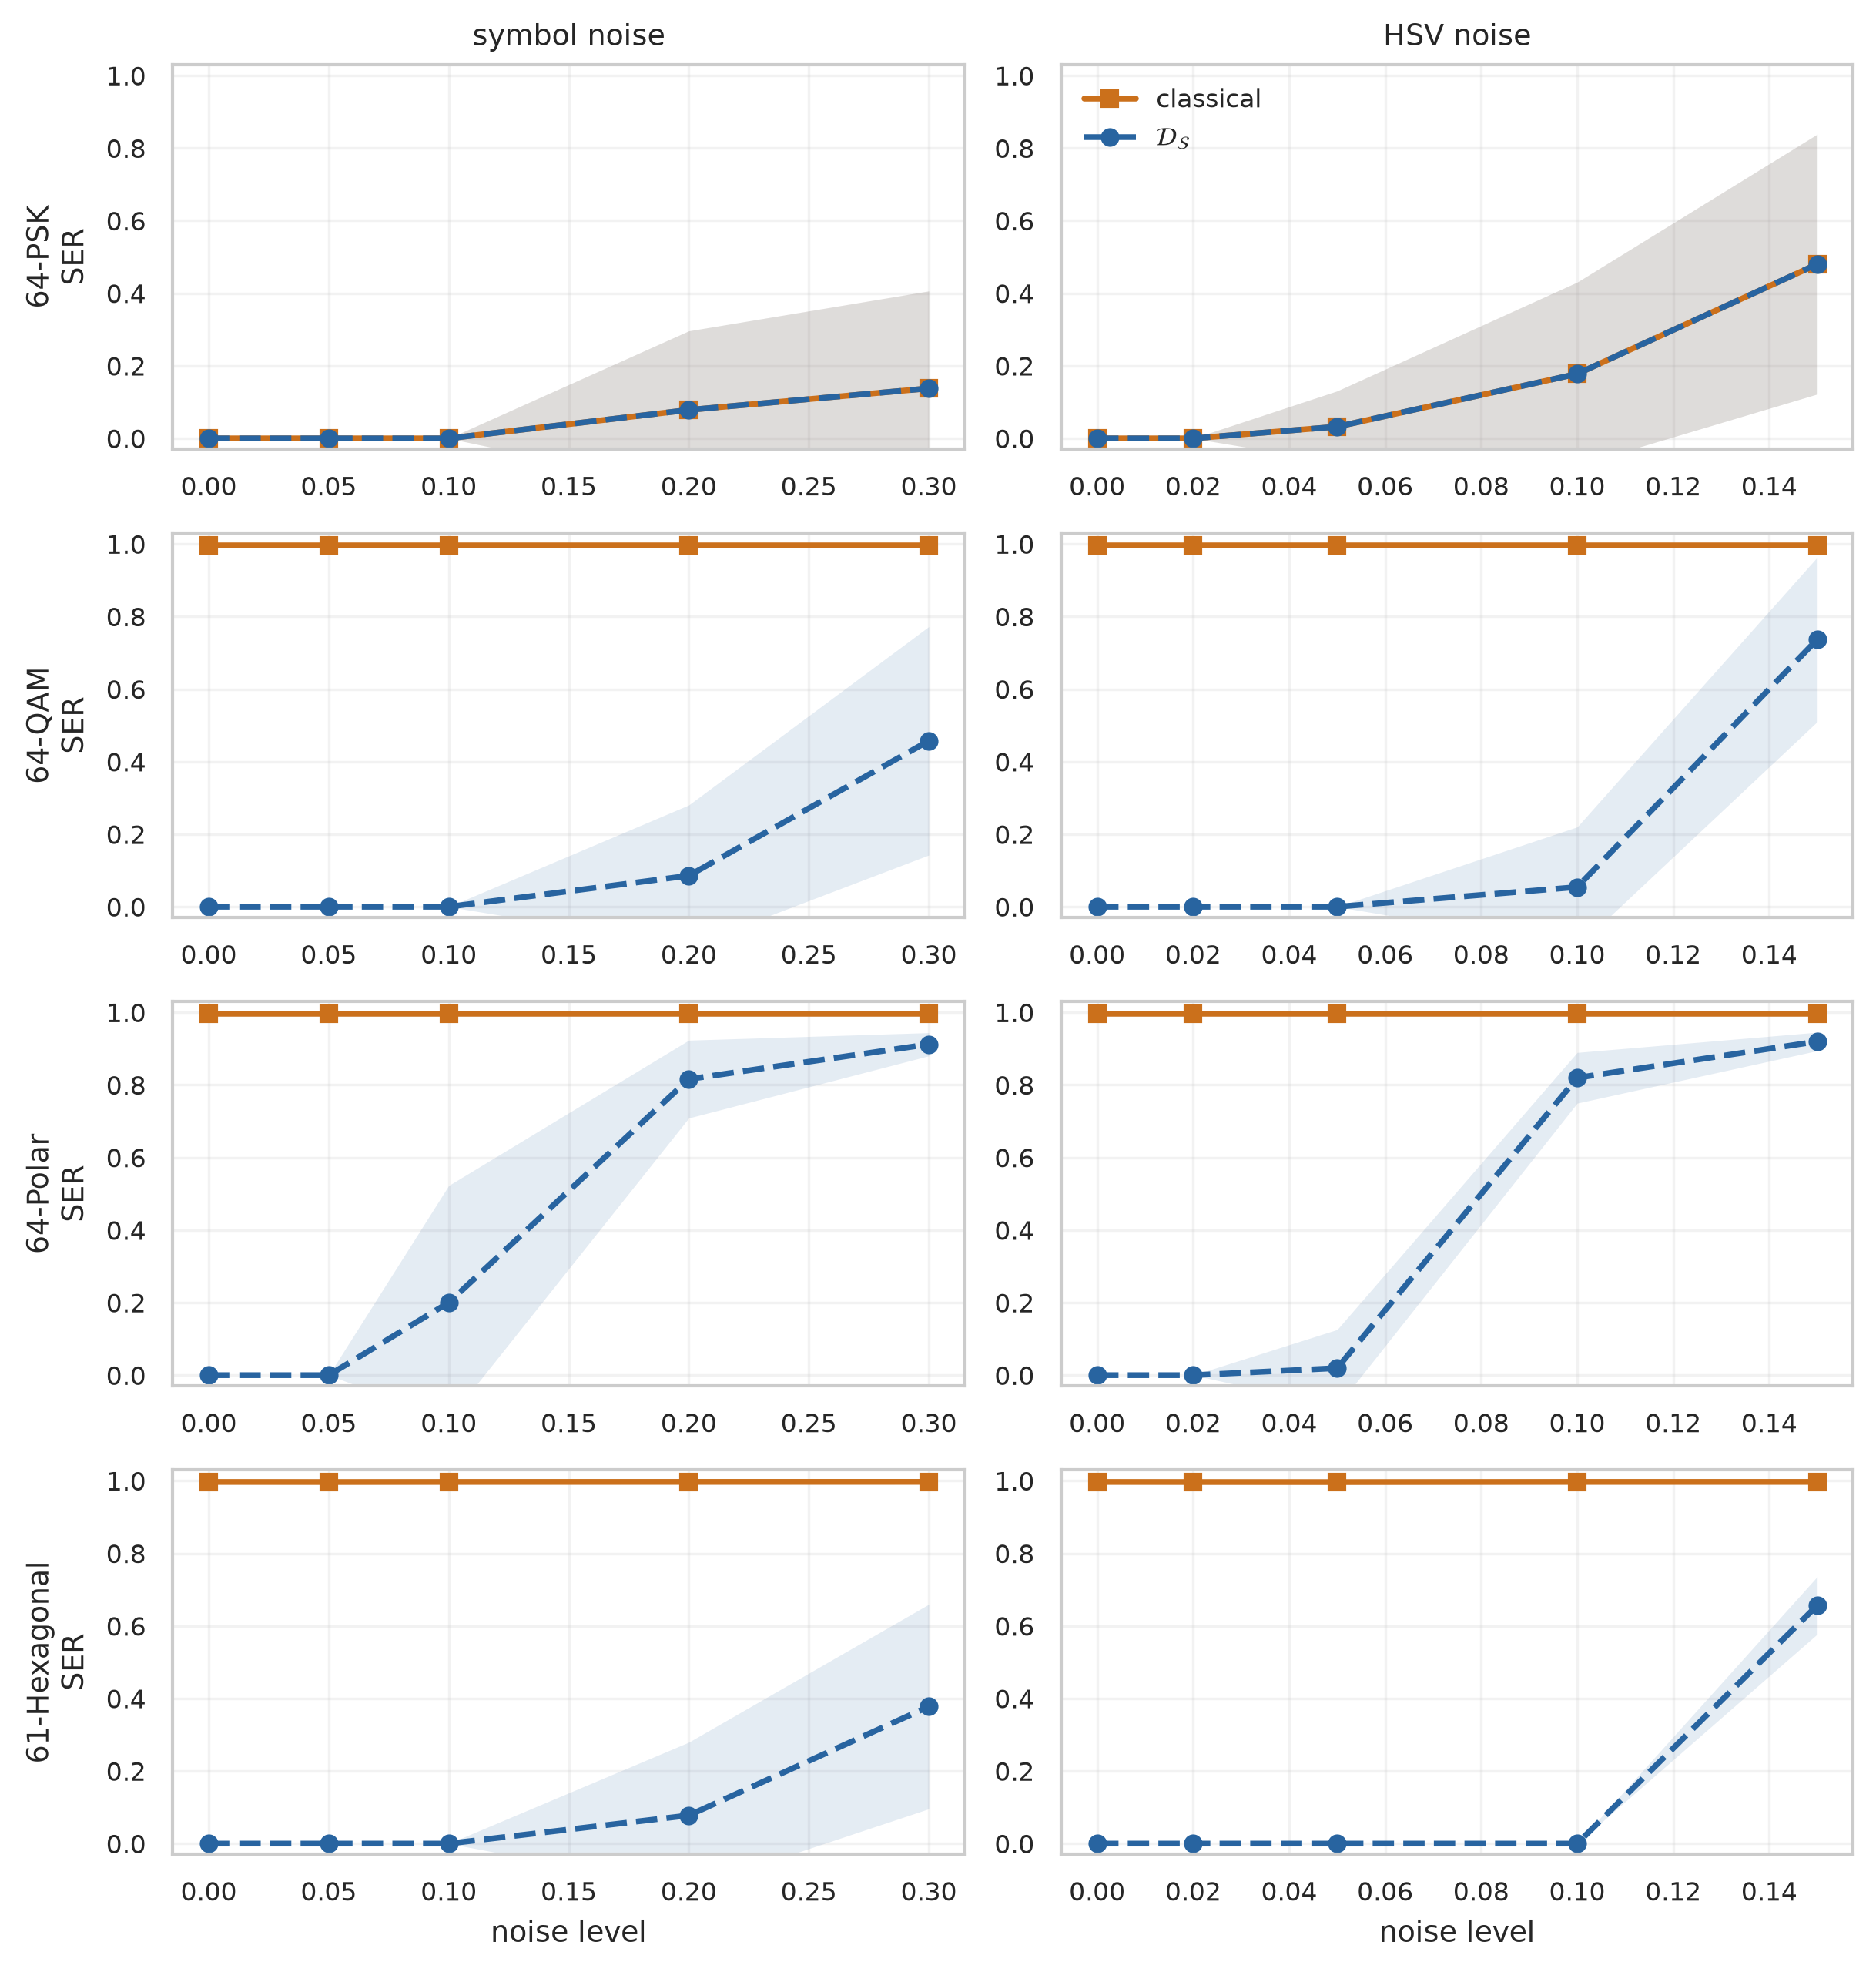

In [5]:
import pandas as pd
data = pd.read_csv(OUTPUT / "experiment2_noise_results.csv")
assert data.converged.all()
assert data.lyapunov_sweep_violations.max() == 0
display(data[data.noise_level == 0.10].groupby(["alphabet", "corruption_kind", "rule"])[["SER", "exact_recovery"]].mean().round(4))
from IPython.display import display, Image
display(Image(filename=str(OUTPUT / "figures/experiment2_noise_SER.png"), width=900))


## Interpretation
Energy descent and target recovery answer different questions. Smoke results are execution checks, not paper estimates. Means and timings must be interpreted with the stated protocol; timing changes between machines are expected. For the full paper comparison, follow `docs/VALIDATION.md` and `docs/USAGE.md`.

## Save the outputs

In [6]:
import shutil
archive = shutil.make_archive(str(OUTPUT) + "_download", "zip", OUTPUT)
if IN_COLAB:
    from google.colab import files
    shutil.copy2(archive, Path("/content") / Path(archive).name)
    print("Output ZIP in the Files sidebar:", Path(archive).name)
    files.download(archive)
else:
    print("Saved:", Path(archive).name)


Saved: 02_hsv_recall_bcc6c840_download.zip
